In [ ]:
# Purpose: Import required libraries.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)

In [ ]:
# Purpose: Load and inspect the original dataset.

df = pd.read_csv("Heart_Disease_Prediction.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nTarget distribution:")
print(df["Heart Disease"].value_counts())

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (270, 14)

Column names:
['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina', 'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium', 'Heart Disease']

First five records:


,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      270 non-null    int64  
 1   Sex                      270 non-null    int64  
 2   Chest pain type          270 non-null    int64  
 3   BP                       270 non-null    int64  
 4   Cholesterol              270 non-null    int64  
 5   FBS over 120             270 non-null    int64  
 6   EKG results              270 non-null    int64  
 7   Max HR                   270 non-null    int64  
 8   Exercise angina          270 non-null    int64  
 9   ST depression            270 non-null    float64
 10  Slope of ST              270 non-null    int64  
 11  Number of vessels fluro  270 non-null    int64  
 12  Thallium                 270 non-null    int64  
 13  Heart Disease            270 non-null    object 
dtypes: f

In [ ]:
# Purpose: Clean the data and standardize the target column.

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

df = df.dropna(axis=0, how="all")
df = df.dropna(axis=1, how="all")
df = df.drop_duplicates()

target_column = "heart_disease"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' was not found.")

df = df.dropna(subset=[target_column]).copy()

target_mapping = {
    "absence": 0,
    "presence": 1
}

target_values = df[target_column].astype(str).str.strip().str.lower()
df["target"] = target_values.map(target_mapping)

if df["target"].isna().any():
    raise ValueError(
        f"Unexpected target values: "
        f"{target_values[df['target'].isna()].unique()}"
    )

df = df.drop(columns=[target_column])

for column in df.columns.drop("target"):
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["target"] = df["target"].astype(int)

print("Cleaned dataset shape:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nTarget distribution (0 = Absence, 1 = Presence):")
print(df["target"].value_counts().sort_index())

display(df.head())

# Save the cleaned dataset.
df.to_csv("heart_disease_cleaned.csv", index=False)
print("\nCleaned dataset saved as heart_disease_cleaned.csv")

Cleaned dataset shape: (270, 14)

Missing values after cleaning:
age                        0
sex                        0
chest_pain_type            0
bp                         0
cholesterol                0
fbs_over_120               0
ekg_results                0
max_hr                     0
exercise_angina            0
st_depression              0
slope_of_st                0
number_of_vessels_fluro    0
thallium                   0
target                     0
dtype: int64

Target distribution (0 = Absence, 1 = Presence):
target
0    150
1    120
Name: count, dtype: int64


,age,sex,chest_pain_type,bp,cholesterol,fbs_over_120,ekg_results,max_hr,exercise_angina,st_depression,slope_of_st,number_of_vessels_fluro,thallium,target
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,1
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,0
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,1
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,0
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,0



Cleaned dataset saved as heart_disease_cleaned.csv


In [ ]:
# Purpose: Separate independent features (X) and target (y).

X = df.drop(columns=["target"])
y = df["target"]

print("Number of input features:", X.shape[1])
print("Number of target records:", y.shape[0])
print("\nFeature columns:")
print(X.columns.tolist())

Number of input features: 13
Number of target records: 270

Feature columns:
['age', 'sex', 'chest_pain_type', 'bp', 'cholesterol', 'fbs_over_120', 'ekg_results', 'max_hr', 'exercise_angina', 'st_depression', 'slope_of_st', 'number_of_vessels_fluro', 'thallium']


In [ ]:
# Purpose: Split data consistently for fair model comparison.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training records: 216
Testing records: 54

Training target distribution:
target
0    120
1     96
Name: count, dtype: int64

Testing target distribution:
target
0    30
1    24
Name: count, dtype: int64


In [ ]:
# Purpose: Define model pipelines with appropriate preprocessing.

models = {
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=42))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(
            criterion="gini",
            max_depth=5,
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", GaussianNB())
    ])
}

print("Models defined:", ", ".join(models.keys()))

Models defined: SVM, Decision Tree, KNN, Naive Bayes


In [ ]:
# Purpose: Train models and evaluate their predictive performance.

results = []
trained_models = {}
predictions = {}
probabilities = {}
confusion_matrices = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    trained_models[name] = model
    predictions[name] = y_pred
    probabilities[name] = y_prob
    confusion_matrices[name] = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Log Loss": log_loss(y_test, y_prob, labels=[0, 1])
    })

results_df = pd.DataFrame(results).set_index("Model")

print("Model evaluation results:")
display(results_df.round(4))

Model evaluation results:


,Accuracy,Precision,Recall,F1-Score,Log Loss
Model,,,,,
SVM,0.8148,0.7692,0.8333,0.8000,0.4475
Decision Tree,0.7963,0.7407,0.8333,0.7843,6.7480
KNN,0.7963,0.7241,0.8750,0.7925,2.2714
Naive Bayes,0.8519,0.8077,0.8750,0.8400,0.8314


In [ ]:
# Purpose: Print detailed classification reports for all models.

for name, y_pred in predictions.items():
    print(f"\n{'=' * 55}")
    print(f"Classification Report: {name}")
    print("=" * 55)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Absence", "Presence"],
            zero_division=0,
            digits=4
        )
    )


Classification Report: SVM
              precision    recall  f1-score   support

     Absence     0.8571    0.8000    0.8276        30
    Presence     0.7692    0.8333    0.8000        24

    accuracy                         0.8148        54
   macro avg     0.8132    0.8167    0.8138        54
weighted avg     0.8181    0.8148    0.8153        54


Classification Report: Decision Tree
              precision    recall  f1-score   support

     Absence     0.8519    0.7667    0.8070        30
    Presence     0.7407    0.8333    0.7843        24

    accuracy                         0.7963        54
   macro avg     0.7963    0.8000    0.7957        54
weighted avg     0.8025    0.7963    0.7969        54


Classification Report: KNN
              precision    recall  f1-score   support

     Absence     0.8800    0.7333    0.8000        30
    Presence     0.7241    0.8750    0.7925        24

    accuracy                         0.7963        54
   macro avg     0.8021    0.8042 

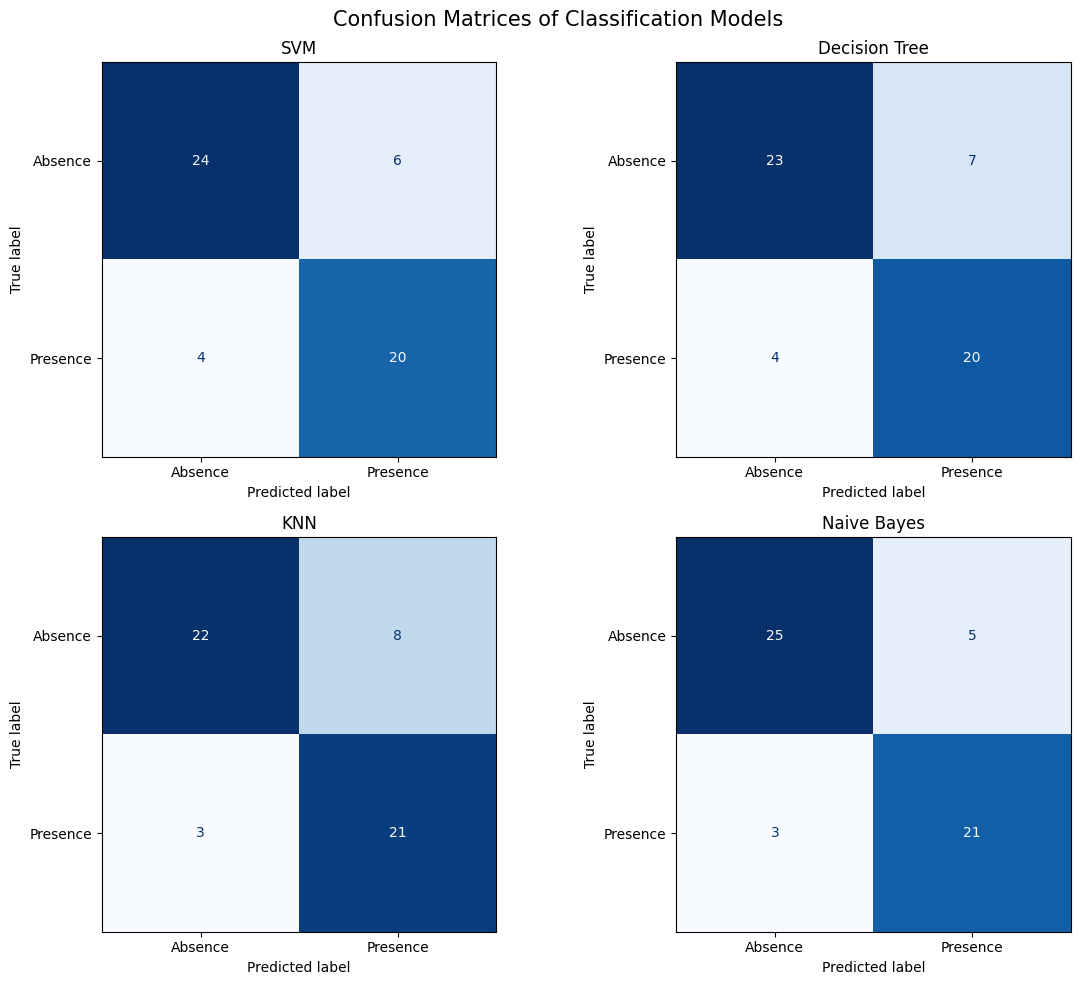

In [ ]:
# Purpose: Compare confusion matrices across the four models.

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrices[name],
        display_labels=["Absence", "Presence"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrices of Classification Models", fontsize=15)
plt.tight_layout()
plt.show()

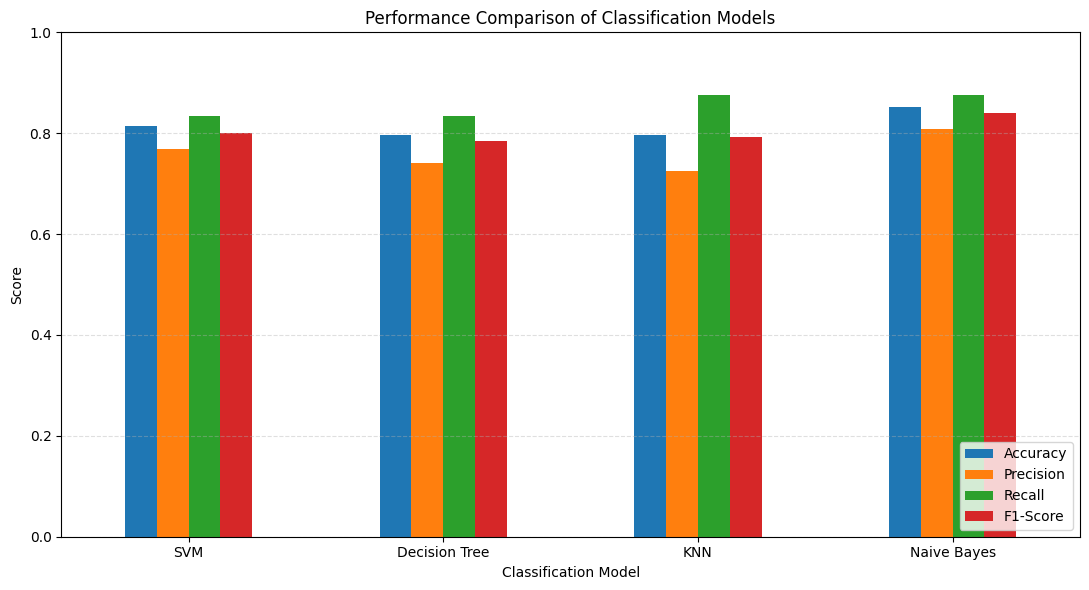

In [ ]:
# Purpose: Plot the main classification metrics.

metric_columns = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df[metric_columns].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Performance Comparison of Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

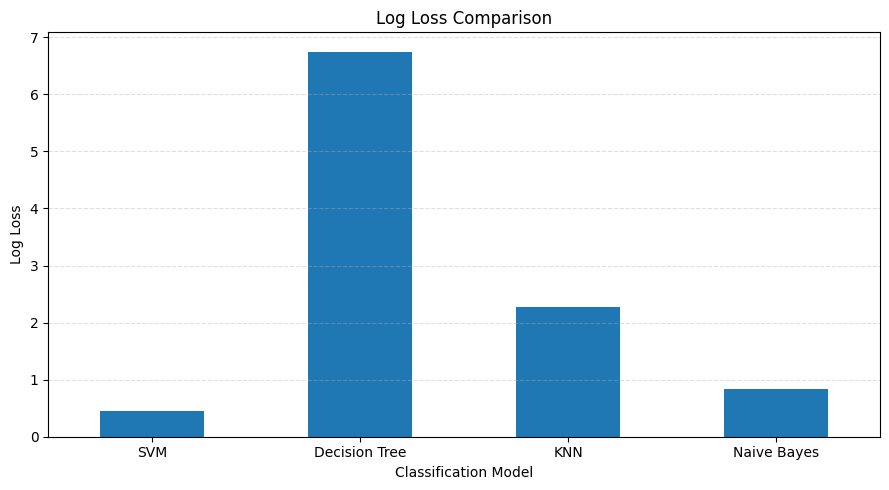

In [ ]:
# Purpose: Plot log loss for each classification model.

results_df["Log Loss"].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Log Loss Comparison")
plt.xlabel("Classification Model")
plt.ylabel("Log Loss")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
# Purpose: Summarize and save the model comparison results.

print("Models ranked by F1-score:")
display(results_df.sort_values("F1-Score", ascending=False).round(4))

best_f1_model = results_df["F1-Score"].idxmax()
best_accuracy_model = results_df["Accuracy"].idxmax()
lowest_loss_model = results_df["Log Loss"].idxmin()

print("\nFinal comparison:")
print(f"Best F1-score: {best_f1_model}")
print(f"Best accuracy: {best_accuracy_model}")
print(f"Lowest log loss: {lowest_loss_model}")

results_df.to_csv("model_comparison_results.csv")

print("\nResults saved to model_comparison_results.csv")

Models ranked by F1-score:


,Accuracy,Precision,Recall,F1-Score,Log Loss
Model,,,,,
Naive Bayes,0.8519,0.8077,0.8750,0.8400,0.8314
SVM,0.8148,0.7692,0.8333,0.8000,0.4475
KNN,0.7963,0.7241,0.8750,0.7925,2.2714
Decision Tree,0.7963,0.7407,0.8333,0.7843,6.7480



Final comparison:
Best F1-score: Naive Bayes
Best accuracy: Naive Bayes
Lowest log loss: SVM

Results saved to model_comparison_results.csv
